In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from math import radians, sin, cos, sqrt, atan2
from xgboost import XGBRegressor
import folium
from folium.plugins import HeatMap
import networkx as nx
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, confusion_matrix, classification_report,
                              ConfusionMatrixDisplay)
sns.set_style('whitegrid')
pd.set_option('display.max_columns', None)
%matplotlib inline

In [ ]:
df = pd.read_csv(
    'sample_data/crime.csv',
    encoding="latin1",
    low_memory=False
)


### 1- ***Analyse Data***

In [ ]:
df.shape

(327820, 17)

In [ ]:
df.head()

,INCIDENT_NUMBER,OFFENSE_CODE,OFFENSE_CODE_GROUP,OFFENSE_DESCRIPTION,DISTRICT,REPORTING_AREA,SHOOTING,OCCURRED_ON_DATE,YEAR,MONTH,DAY_OF_WEEK,HOUR,UCR_PART,STREET,Lat,Long,Location
0,I182080058,2403,Disorderly Conduct,DISTURBING THE PEACE,E18,495,NaN,2018-10-03 20:13:00,2018,10,Wednesday,20,Part Two,ARLINGTON ST,42.262608,-71.121186,"(42.26260773, -71.12118637)"
1,I182080053,3201,Property Lost,PROPERTY - LOST,D14,795,NaN,2018-08-30 20:00:00,2018,8,Thursday,20,Part Three,ALLSTON ST,42.352111,-71.135311,"(42.35211146, -71.13531147)"
2,I182080052,2647,Other,THREATS TO DO BODILY HARM,B2,329,NaN,2018-10-03 19:20:00,2018,10,Wednesday,19,Part Two,DEVON ST,42.308126,-71.076930,"(42.30812619, -71.07692974)"
3,I182080051,413,Aggravated Assault,ASSAULT - AGGRAVATED - BATTERY,A1,92,NaN,2018-10-03 20:00:00,2018,10,Wednesday,20,Part One,CAMBRIDGE ST,42.359454,-71.059648,"(42.35945371, -71.05964817)"
4,I182080050,3122,Aircraft,AIRCRAFT INCIDENTS,A7,36,NaN,2018-10-03 20:49:00,2018,10,Wednesday,20,Part Three,PRESCOTT ST,42.375258,-71.024663,"(42.37525782, -71.02466343)"


In [ ]:
df.isnull().sum()

,0
INCIDENT_NUMBER,0
OFFENSE_CODE,0
OFFENSE_CODE_GROUP,0
OFFENSE_DESCRIPTION,0
DISTRICT,1774
REPORTING_AREA,0
SHOOTING,326765
OCCURRED_ON_DATE,0
YEAR,0
MONTH,0


In [ ]:
df.describe()

,OFFENSE_CODE,YEAR,MONTH,HOUR,Lat,Long
count,327820.000000,327820.000000,327820.000000,327820.000000,307188.000000,307188.000000
mean,2317.961171,2016.598676,6.672213,13.114840,42.212995,-70.906030
std,1184.990073,1.009775,3.253984,6.292714,2.173496,3.515832
min,111.000000,2015.000000,1.000000,0.000000,-1.000000,-71.178674
25%,1001.000000,2016.000000,4.000000,9.000000,42.297466,-71.097081
50%,2907.000000,2017.000000,7.000000,14.000000,42.325552,-71.077493
75%,3201.000000,2017.000000,9.000000,18.000000,42.348624,-71.062482
max,3831.000000,2018.000000,12.000000,23.000000,42.395042,-1.000000


2- ***Data Preprocessing***




1-filled nulls in Lat and Long with zeros

2-dropped feature "Location" as it doesn't add anything to the actual data. Lat and Long already describe the location (Location is the combination of both Lat and Long)

3-filled nulls in shootings with N
{ shootings define the existance of shootings with Y in case there was and Nan in case there wasn't)  

5-filled nulls in district with nearest neighbor

6-filled nulls in UCR_PART with the suitable category

7-Calculate total_weight

8-drop high cardinality features

9-drop duplicates

10- encode categorical features

In [ ]:
df[df['Lat'].isnull()].head()

,INCIDENT_NUMBER,OFFENSE_CODE,OFFENSE_CODE_GROUP,OFFENSE_DESCRIPTION,DISTRICT,REPORTING_AREA,SHOOTING,OCCURRED_ON_DATE,YEAR,MONTH,DAY_OF_WEEK,HOUR,UCR_PART,STREET,Lat,Long,Location
150,I182079891,413,Aggravated Assault,ASSAULT - AGGRAVATED - BATTERY,C6,,NaN,2018-10-03 12:53:00,2018,10,Wednesday,12,Part One,DORCHESTER ST,NaN,NaN,"(0.00000000, 0.00000000)"
151,I182079891,3125,Warrant Arrests,WARRANT ARREST,C6,,NaN,2018-10-03 12:53:00,2018,10,Wednesday,12,Part Three,DORCHESTER ST,NaN,NaN,"(0.00000000, 0.00000000)"
216,I182079820,1402,Vandalism,VANDALISM,C11,,NaN,2018-10-03 05:00:00,2018,10,Wednesday,5,Part Two,BOWDOIN ST,NaN,NaN,"(0.00000000, 0.00000000)"
220,I182079816,1402,Vandalism,VANDALISM,C11,,NaN,2018-10-02 20:00:00,2018,10,Tuesday,20,Part Two,BOWDOIN ST,NaN,NaN,"(0.00000000, 0.00000000)"
248,I182079784,802,Simple Assault,ASSAULT SIMPLE - BATTERY,C11,355,NaN,2018-10-03 03:07:00,2018,10,Wednesday,3,Part Two,NaN,NaN,NaN,"(0.00000000, 0.00000000)"


In [ ]:
df['Lat'] = df['Lat'].fillna(0)
df['Long'] = df['Long'].fillna(0)

In [ ]:
df.isnull().sum()

,0
INCIDENT_NUMBER,0
OFFENSE_CODE,0
OFFENSE_CODE_GROUP,0
OFFENSE_DESCRIPTION,0
DISTRICT,1774
REPORTING_AREA,0
SHOOTING,326765
OCCURRED_ON_DATE,0
YEAR,0
MONTH,0


In [ ]:
from sklearn.neighbors import NearestNeighbors

df_known = df[df['DISTRICT'].notna()].copy()
df_unknown = df[df['DISTRICT'].isna()].copy()


if not df_unknown.empty:
    coords_known = np.radians(df_known[['Lat', 'Long']].values)
    coords_unknown = np.radians(df_unknown[['Lat', 'Long']].values)
    nn_model = NearestNeighbors(n_neighbors=1, algorithm='ball_tree', metric='haversine')
    nn_model.fit(coords_known)
    distances, indices = nn_model.kneighbors(coords_unknown)
    nearest_districts = df_known['DISTRICT'].iloc[indices.flatten()].values
    df.loc[df['DISTRICT'].isna(), 'DISTRICT'] = nearest_districts

print("Nulls in 'DISTRICT' after imputation:")
print(df['DISTRICT'].isnull().sum())

Nulls in 'DISTRICT' after imputation:
0


In [ ]:
df[df['UCR_PART'].isnull()].head()

,INCIDENT_NUMBER,OFFENSE_CODE,OFFENSE_CODE_GROUP,OFFENSE_DESCRIPTION,DISTRICT,REPORTING_AREA,SHOOTING,OCCURRED_ON_DATE,YEAR,MONTH,DAY_OF_WEEK,HOUR,UCR_PART,STREET,Lat,Long,Location
145,I182079896,2010,HOME INVASION,HOME INVASION,E18,501,NaN,2018-10-03 13:06:00,2018,10,Wednesday,13,NaN,STELLA RD,42.281047,-71.116990,"(42.28104731, -71.11698982)"
1470,I182078432,2010,HOME INVASION,HOME INVASION,E18,527,NaN,2018-09-28 11:31:00,2018,9,Friday,11,NaN,HYDE PARK AVE,42.235047,-71.132892,"(42.23504691, -71.13289238)"
7624,I182071765,2010,HOME INVASION,HOME INVASION,B3,431,NaN,2018-09-06 12:26:00,2018,9,Thursday,12,NaN,LUCERNE ST,42.287923,-71.088158,"(42.28792347, -71.08815774)"
9726,I182069560,2010,HOME INVASION,HOME INVASION,C6,915,NaN,2018-08-30 08:19:00,2018,8,Thursday,8,NaN,E NINTH ST,42.331463,-71.050126,"(42.33146325, -71.05012560)"
17794,I182060810,2010,HOME INVASION,HOME INVASION,E18,493,NaN,2018-08-01 14:52:00,2018,8,Wednesday,14,NaN,REDDY AVE,42.262855,-71.111811,"(42.26285498, -71.11181148)"


In [ ]:
print(df['UCR_PART'].mode())

0    Part Three
Name: UCR_PART, dtype: object


In [ ]:
mapping = {
    'HOME INVASION': 'Part One',
    'HUMAN TRAFFICKING': 'Part One',
    'HUMAN TRAFFICKING - INVOLUNTARY SERVITUDE': 'Part One',
    'INVESTIGATE PERSON': 'Part Three'
}

df['UCR_PART'] = df['UCR_PART'].fillna(df['OFFENSE_CODE_GROUP'].map(mapping))

In [ ]:
df = df.drop(columns = 'Location')
df.shape

(327820, 16)

In [ ]:
df.drop_duplicates(inplace=True)
df.shape

(327797, 16)

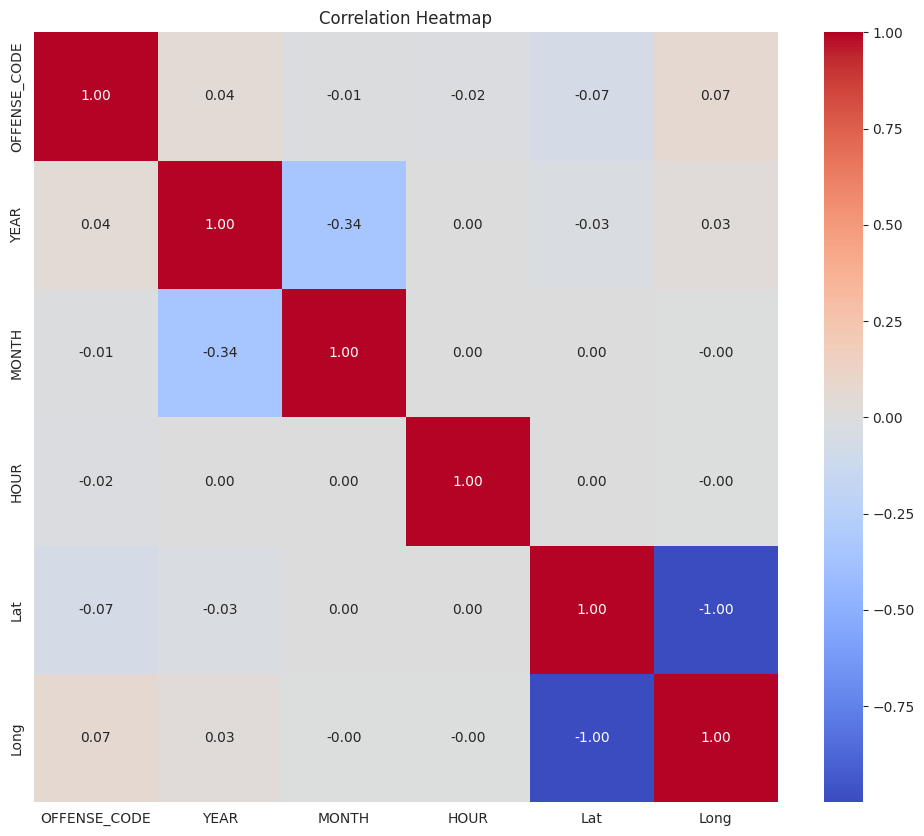

In [ ]:
plt.figure(figsize=(12, 10))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

In [ ]:
df.nunique()

,0
INCIDENT_NUMBER,290156
OFFENSE_CODE,222
OFFENSE_CODE_GROUP,67
OFFENSE_DESCRIPTION,244
DISTRICT,12
REPORTING_AREA,880
SHOOTING,1
OCCURRED_ON_DATE,239364
YEAR,4
MONTH,12


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 327797 entries, 0 to 327819
Data columns (total 16 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   INCIDENT_NUMBER      327797 non-null  object 
 1   OFFENSE_CODE         327797 non-null  int64  
 2   OFFENSE_CODE_GROUP   327797 non-null  object 
 3   OFFENSE_DESCRIPTION  327797 non-null  object 
 4   DISTRICT             327797 non-null  object 
 5   REPORTING_AREA       327797 non-null  object 
 6   SHOOTING             1055 non-null    object 
 7   OCCURRED_ON_DATE     327797 non-null  object 
 8   YEAR                 327797 non-null  int64  
 9   MONTH                327797 non-null  int64  
 10  DAY_OF_WEEK          327797 non-null  object 
 11  HOUR                 327797 non-null  int64  
 12  UCR_PART             327797 non-null  object 
 13  STREET               316820 non-null  object 
 14  Lat                  327797 non-null  float64
 15  Long                 3

In [ ]:
df['SHOOTING'] = df['SHOOTING'].fillna('N')

In [ ]:
df = df.drop(columns = 'STREET')

In [ ]:
df = df.drop(columns = 'INCIDENT_NUMBER')

In [ ]:
df.isnull().sum()

,0
OFFENSE_CODE,0
OFFENSE_CODE_GROUP,0
OFFENSE_DESCRIPTION,0
DISTRICT,0
REPORTING_AREA,0
SHOOTING,0
OCCURRED_ON_DATE,0
YEAR,0
MONTH,0
DAY_OF_WEEK,0


In [ ]:
severity_map = {'Part One': 3, 'Part Two': 2, 'Part Three': 1 , 'Other' : 1}
df['severity_weight'] = df['UCR_PART'].map(severity_map)

df['shooting_flag'] = df['SHOOTING'].fillna(0).apply(lambda x: 1 if str(x).upper() in ['Y', '1'] else 0)
df['total_weight'] = df['severity_weight'] + (df['shooting_flag'] * 5)

weighted_risk = df.groupby(['DISTRICT', 'HOUR'])['total_weight'].sum().reset_index(name='raw_risk_score')

weighted_risk['crime_risk_index'] = (
    (weighted_risk['raw_risk_score'] - weighted_risk['raw_risk_score'].min()) /
    (weighted_risk['raw_risk_score'].max() - weighted_risk['raw_risk_score'].min())
) * 100

In [ ]:
df.head()

,OFFENSE_CODE,OFFENSE_CODE_GROUP,OFFENSE_DESCRIPTION,DISTRICT,REPORTING_AREA,SHOOTING,OCCURRED_ON_DATE,YEAR,MONTH,DAY_OF_WEEK,HOUR,UCR_PART,Lat,Long,severity_weight,shooting_flag,total_weight
0,2403,Disorderly Conduct,DISTURBING THE PEACE,E18,495,N,2018-10-03 20:13:00,2018,10,Wednesday,20,Part Two,42.262608,-71.121186,2,0,2
1,3201,Property Lost,PROPERTY - LOST,D14,795,N,2018-08-30 20:00:00,2018,8,Thursday,20,Part Three,42.352111,-71.135311,1,0,1
2,2647,Other,THREATS TO DO BODILY HARM,B2,329,N,2018-10-03 19:20:00,2018,10,Wednesday,19,Part Two,42.308126,-71.076930,2,0,2
3,413,Aggravated Assault,ASSAULT - AGGRAVATED - BATTERY,A1,92,N,2018-10-03 20:00:00,2018,10,Wednesday,20,Part One,42.359454,-71.059648,3,0,3
4,3122,Aircraft,AIRCRAFT INCIDENTS,A7,36,N,2018-10-03 20:49:00,2018,10,Wednesday,20,Part Three,42.375258,-71.024663,1,0,1


In [ ]:
df.describe()

,OFFENSE_CODE,YEAR,MONTH,HOUR,Lat,Long,severity_weight,shooting_flag,total_weight
count,327797.000000,327797.000000,327797.000000,327797.000000,327797.000000,327797.000000,327797.000000,327797.000000,327797.000000
mean,2317.932001,2016.598764,6.672123,13.114812,39.556171,-66.443311,1.692242,0.003218,1.708335
std,1185.012823,1.009742,3.253971,6.292765,10.465221,17.552831,0.774193,0.056640,0.839631
min,111.000000,2015.000000,1.000000,0.000000,-1.000000,-71.178674,1.000000,0.000000,1.000000
25%,1001.000000,2016.000000,4.000000,9.000000,42.290732,-71.095263,1.000000,0.000000,1.000000
50%,2907.000000,2017.000000,7.000000,14.000000,42.321060,-71.075589,1.000000,0.000000,1.000000
75%,3201.000000,2017.000000,9.000000,18.000000,42.347106,-71.060002,2.000000,0.000000,2.000000
max,3831.000000,2018.000000,12.000000,23.000000,42.395042,0.000000,3.000000,1.000000,8.000000


In [ ]:
weighted_risk.shape

(288, 4)

In [ ]:
weighted_risk.head()

,DISTRICT,HOUR,raw_risk_score,crime_risk_index
0,A1,0,3721,62.068376
1,A1,1,3229,53.658120
2,A1,2,3039,50.410256
3,A1,3,1215,19.230769
4,A1,4,744,11.179487


In [ ]:
df = df.drop(columns = ['UCR_PART', 'SHOOTING'])

In [ ]:
df = df.drop(columns = ['OFFENSE_CODE_GROUP', 'OFFENSE_DESCRIPTION', 'OCCURRED_ON_DATE','REPORTING_AREA'])

In [ ]:
df.shape

(327797, 11)

In [ ]:
df.head()

,OFFENSE_CODE,DISTRICT,YEAR,MONTH,DAY_OF_WEEK,HOUR,Lat,Long,severity_weight,shooting_flag,total_weight
0,2403,E18,2018,10,Wednesday,20,42.262608,-71.121186,2,0,2
1,3201,D14,2018,8,Thursday,20,42.352111,-71.135311,1,0,1
2,2647,B2,2018,10,Wednesday,19,42.308126,-71.076930,2,0,2
3,413,A1,2018,10,Wednesday,20,42.359454,-71.059648,3,0,3
4,3122,A7,2018,10,Wednesday,20,42.375258,-71.024663,1,0,1


In [ ]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['DAY'] = le.fit_transform(df['DAY_OF_WEEK'])
df = df.drop(columns=['DAY_OF_WEEK'])
print(df[['DAY']].head())

   DAY
0    6
1    4
2    6
3    6
4    6


In [ ]:
df.head()

,OFFENSE_CODE,DISTRICT,YEAR,MONTH,HOUR,Lat,Long,severity_weight,shooting_flag,total_weight,DAY
0,2403,E18,2018,10,20,42.262608,-71.121186,2,0,2,6
1,3201,D14,2018,8,20,42.352111,-71.135311,1,0,1,4
2,2647,B2,2018,10,19,42.308126,-71.076930,2,0,2,6
3,413,A1,2018,10,20,42.359454,-71.059648,3,0,3,6
4,3122,A7,2018,10,20,42.375258,-71.024663,1,0,1,6


***3-Exploratory Data Analysis***

In [ ]:
print(df.skew(numeric_only=True))

OFFENSE_CODE       -0.410582
YEAR               -0.083871
MONTH              -0.119548
HOUR               -0.482930
Lat                -3.519067
Long                3.519020
severity_weight     0.592155
shooting_flag      17.541782
total_weight        1.506933
DAY                -0.006557
dtype: float64


DO NOT TRANSFORM SHOOTING FLAG!!!!!

it's a binary classification indicator

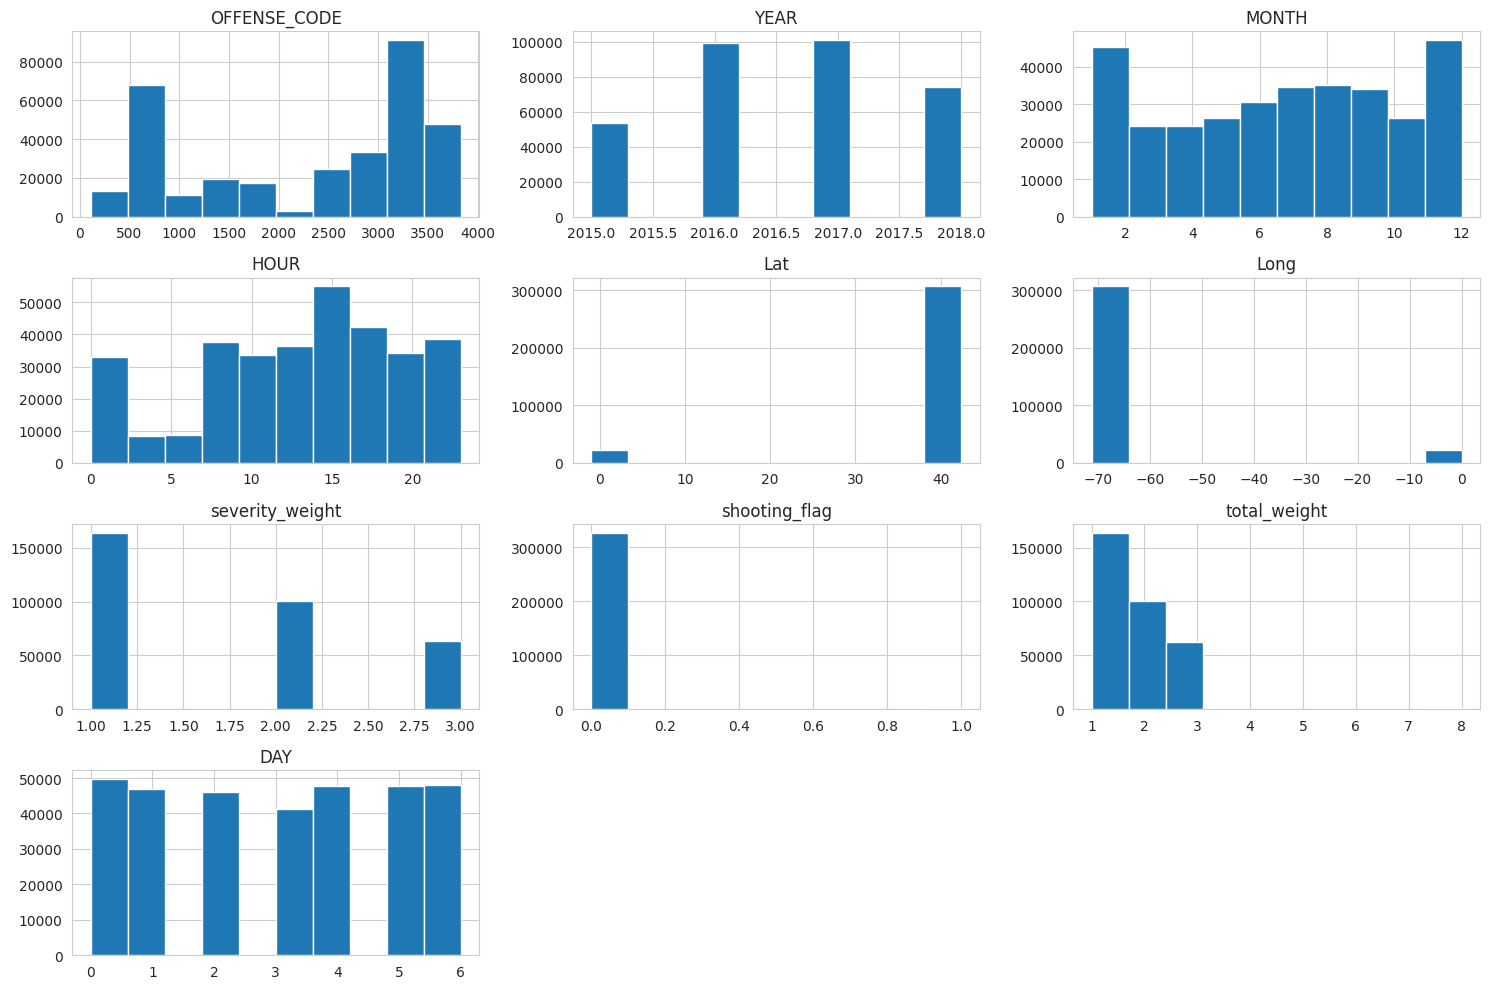

In [ ]:
df.hist(figsize=(15, 10));
plt.tight_layout()
plt.show()

In [ ]:
df['total_weight'] = np.log1p(df['total_weight'])

In [ ]:
df = df[(df['Lat'] > 40) & (df['Long'] < -70)]
print(df.shape)

(306391, 11)


In [ ]:
print(df.skew(numeric_only=True))

OFFENSE_CODE       -0.395374
YEAR               -0.079442
MONTH              -0.120239
HOUR               -0.480503
Lat                -0.228903
Long               -0.697587
severity_weight     0.576035
shooting_flag      17.262089
total_weight        0.548819
DAY                -0.006221
dtype: float64


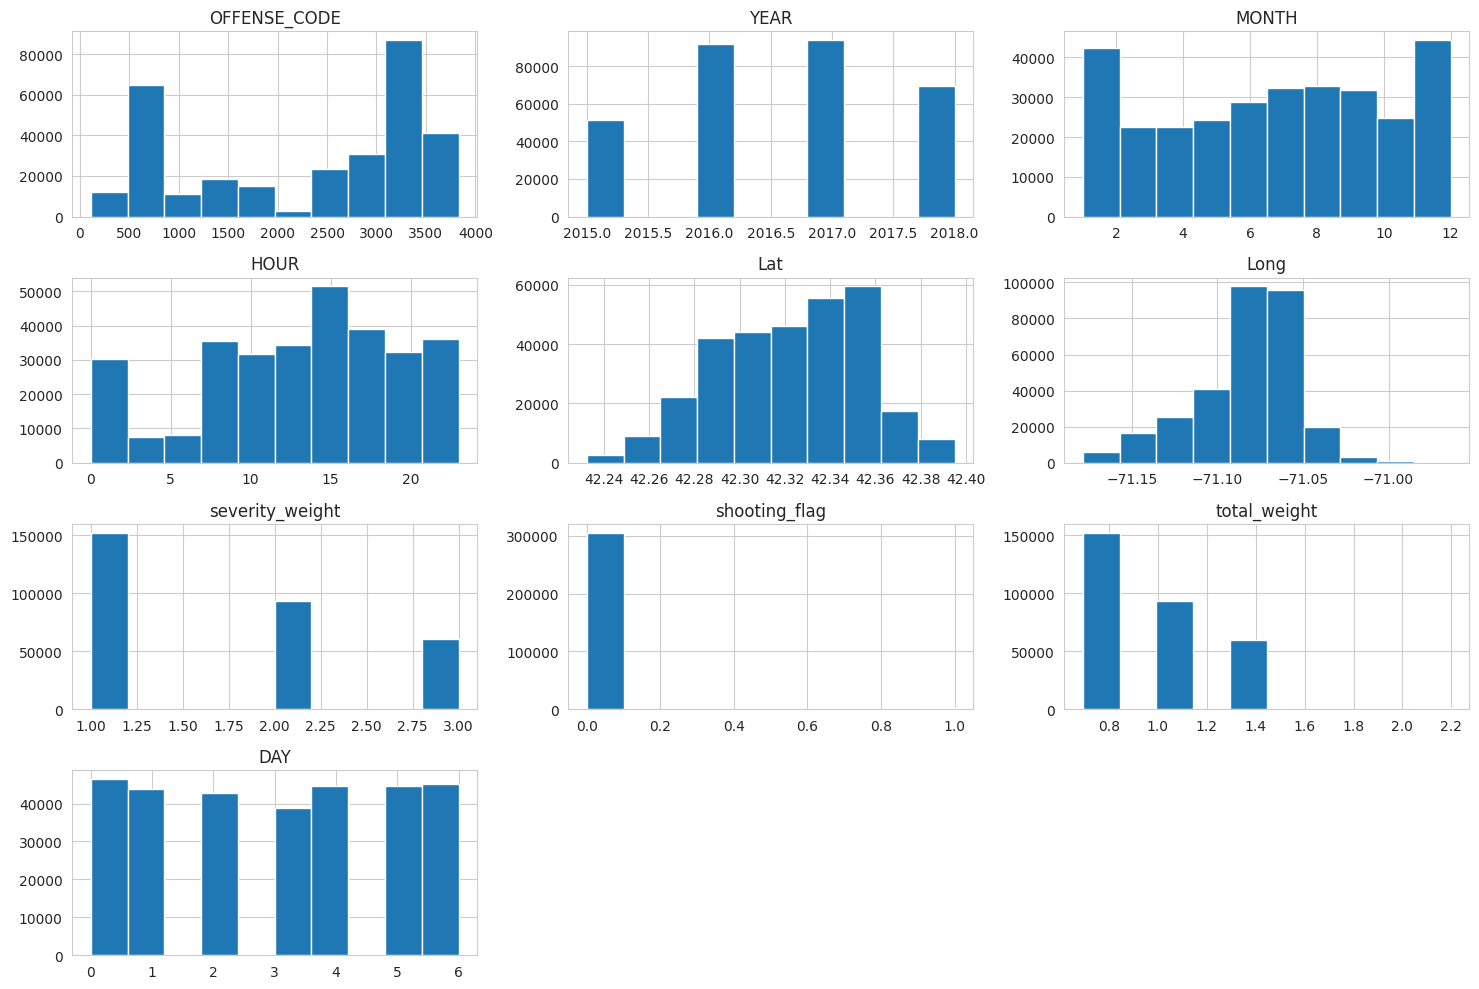

In [ ]:
df.hist(figsize=(15, 10));
plt.tight_layout()
plt.show()

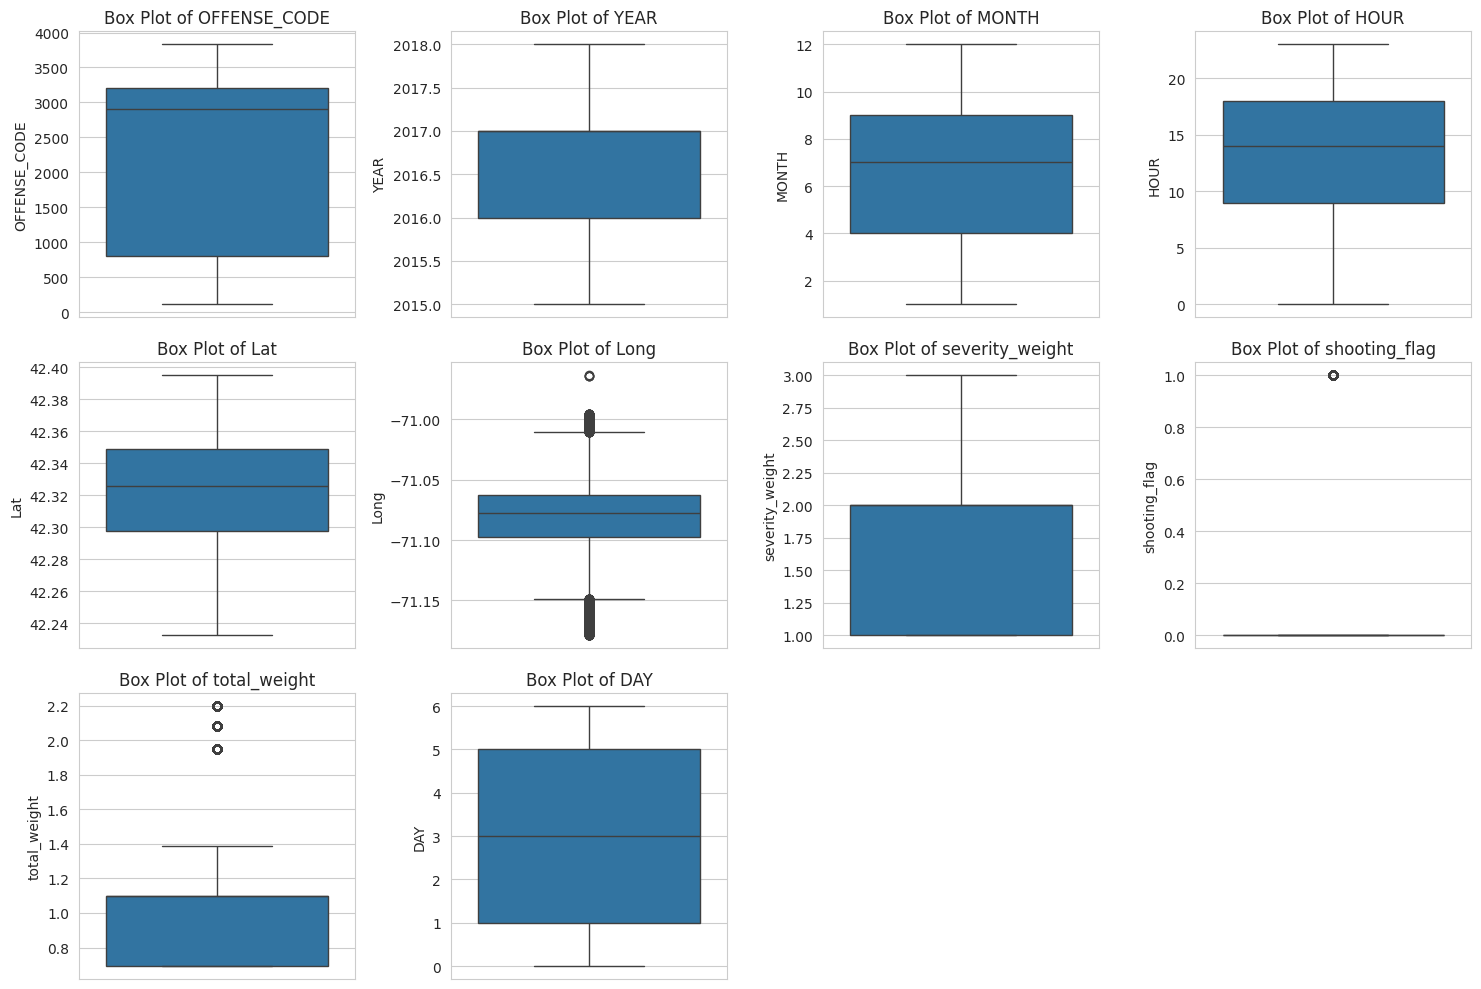

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 10))
for i, col in enumerate(df.select_dtypes(include=np.number).columns):
    plt.subplot(3, 4, i + 1)
    sns.boxplot(y=df[col])
    plt.title(f'Box Plot of {col}')
plt.tight_layout()
plt.show()

### Bivariate Analysis

#### `total_weight` vs `DISTRICT`

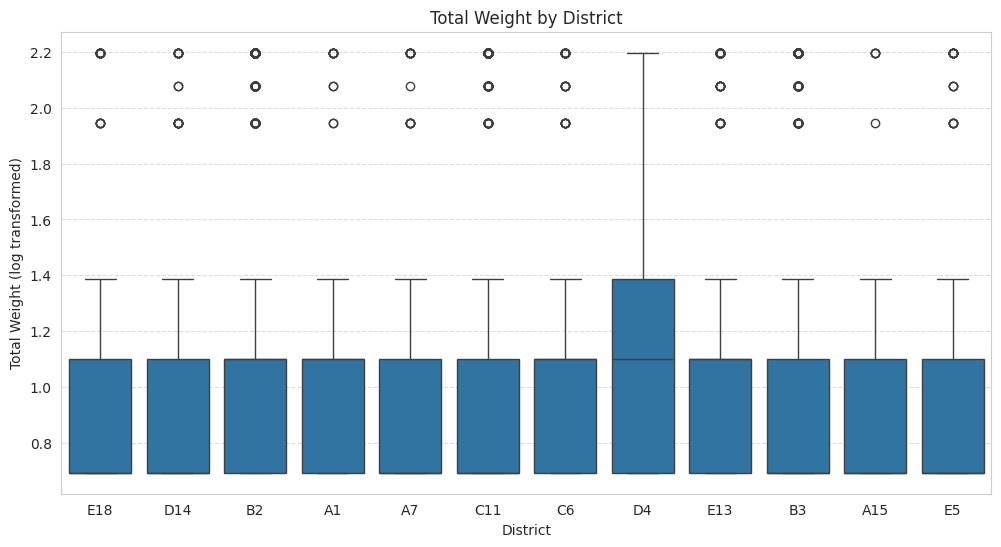

In [ ]:
plt.figure(figsize=(12, 6))
sns.boxplot(x='DISTRICT', y='total_weight', data=df)
plt.title('Total Weight by District')
plt.xlabel('District')
plt.ylabel('Total Weight (log transformed)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

The district with the highest median total weight is D4.

Median Value: The median of each box plot is represented by the horizontal line inside the blue box. For almost all districts (E18, D14, B2, A1, etc.), the median line rests near the bottom boundary around 0.7 or 1.1.

District D4: The median horizontal line inside the box for D4 sits significantly higher at approximately 1.1, while its upper quartile (top of the box) extends up to nearly 1.4 and its upper whisker reaches all the way to 2.2.

#### `DISTRICT` vs `DAY`

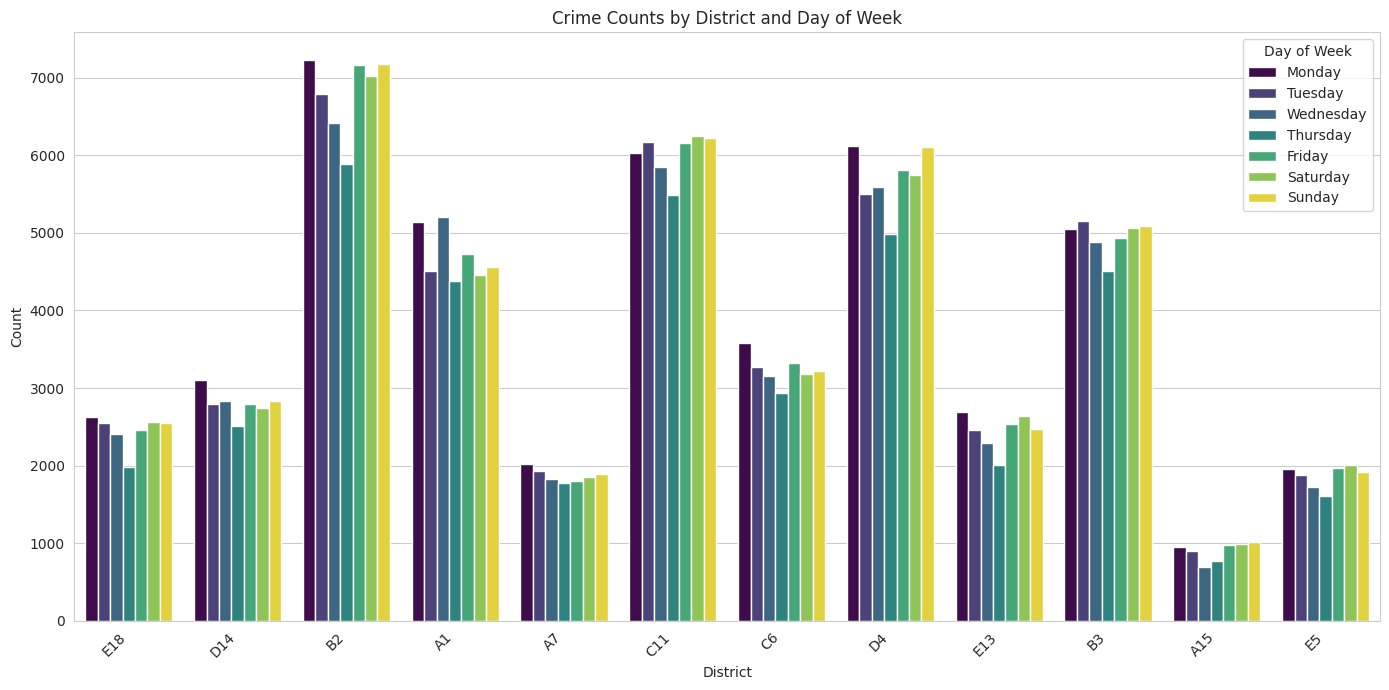

In [ ]:
plt.figure(figsize=(14, 7))
sns.countplot(x='DISTRICT', hue='DAY', data=df, palette='viridis')
plt.title('Crime Counts by District and Day of Week')
plt.xlabel('District')
plt.ylabel('Count')
plt.legend(title='Day of Week', labels=['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday'])
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

Highest Overall Volume (District B2): District B2 records the highest crime counts across all days, peaking at well over 7,000 counts (specifically on Monday, Friday, Saturday, and Sunday).

Lowest Overall Volume (District A15): District A15 records the lowest crime counts across all days, staying consistently below 1,000 counts.

Other High-Volume Districts: C11 and D4 also show high crime activity, with daily counts ranging mostly between 5,000 and 6,200.

Day of Week Patterns:

In many high-crime districts like B2, C11, and D4, crime counts tend to be highest at the start of the week (Monday) and during the weekend (Friday–Sunday), with slight dips mid-week (Thursday).

In most districts, Thursday (represented by the teal bar) shows the lowest or near-lowest count of the week.

In [ ]:
df['District'] = df['DISTRICT'].astype('category').cat.codes

### Random Forest

### Random Forest

Same task (predict `HIGH_RISK` district/hour/day/month cells), but with:
- Cyclical encoding of `HOUR` and `MONTH` instead of treating them as plain integers
- `is_weekend` / `is_night` flags and a district-level historical average as extra signal
- `class_weight` tuned to address the ~15%/85% class imbalance from the quantile threshold
- A wider hyperparameter search (`RandomizedSearchCV`, 5-fold stratified CV, 40 draws) instead of the small 3-fold grid
- ROC-AUC / PR-AUC reported alongside F1 since PR-AUC is more informative for an imbalanced target


              precision    recall  f1-score   support

           0       0.97      0.90      0.94      3954
           1       0.62      0.87      0.73       740

    accuracy                           0.90      4694
   macro avg       0.80      0.89      0.83      4694
weighted avg       0.92      0.90      0.90      4694

ROC-AUC: 0.958
PR-AUC (average precision): 0.818
Best Parameters: {'n_estimators': 300, 'min_samples_split': 10, 'min_samples_leaf': 2, 'max_features': 0.5, 'max_depth': 16, 'class_weight': 'balanced'}


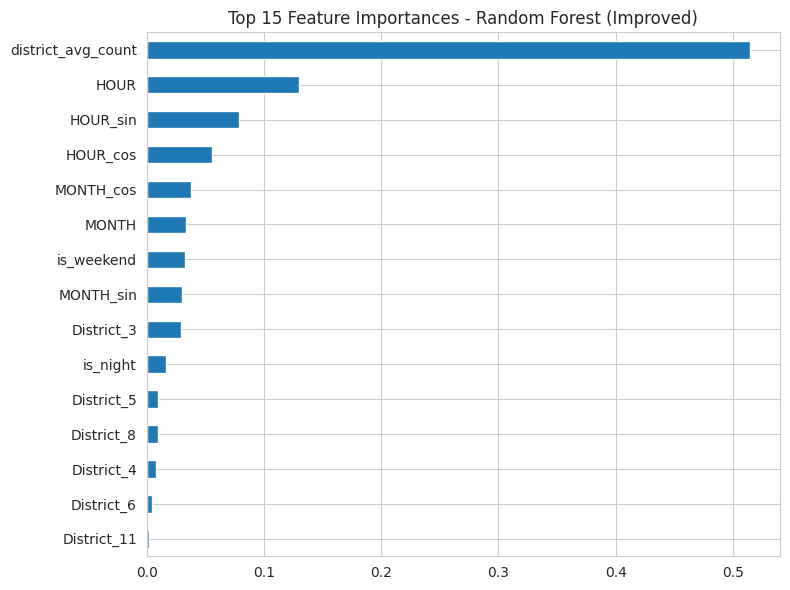

In [ ]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import roc_auc_score, average_precision_score

# --- same base aggregation as before ---
spatial_time_group = df.groupby(['District', 'HOUR', 'DAY', 'MONTH']).size().reset_index(name='crime_count_agg')

threshold_risk = spatial_time_group['crime_count_agg'].quantile(0.85)
spatial_time_group['HIGH_RISK'] = (spatial_time_group['crime_count_agg'] >= threshold_risk).astype(int)

# --- extra feature engineering ---
spatial_time_group['HOUR_sin'] = np.sin(2 * np.pi * spatial_time_group['HOUR'] / 24)
spatial_time_group['HOUR_cos'] = np.cos(2 * np.pi * spatial_time_group['HOUR'] / 24)
spatial_time_group['MONTH_sin'] = np.sin(2 * np.pi * spatial_time_group['MONTH'] / 12)
spatial_time_group['MONTH_cos'] = np.cos(2 * np.pi * spatial_time_group['MONTH'] / 12)
spatial_time_group['is_night'] = spatial_time_group['HOUR'].apply(lambda h: 1 if (h >= 22 or h <= 5) else 0)

weekend_codes = {i for i, name in enumerate(le.classes_) if name in ('Saturday', 'Sunday')}
spatial_time_group['is_weekend'] = spatial_time_group['DAY'].isin(weekend_codes).astype(int)

spatial_time_group['district_avg_count'] = spatial_time_group.groupby('District')['crime_count_agg'].transform('mean')

feature_cols = ['District', 'HOUR', 'MONTH', 'HOUR_sin', 'HOUR_cos', 'MONTH_sin', 'MONTH_cos',
                'is_weekend', 'is_night', 'district_avg_count']
X = spatial_time_group[feature_cols]
y = spatial_time_group['HIGH_RISK']

X = pd.get_dummies(X, columns=['District'], drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

param_dist = {
    'n_estimators': [200, 300, 400, 600],
    'max_depth': [8, 12, 16, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2', 0.5],
    'class_weight': ['balanced', 'balanced_subsample', None],
}

base_rf = RandomForestClassifier(random_state=42, n_jobs=-1)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

random_search = RandomizedSearchCV(
    estimator=base_rf,
    param_distributions=param_dist,
    n_iter=40,
    cv=cv,
    scoring='f1',
    n_jobs=-1,
    random_state=42,
)
random_search.fit(X_train, y_train)

best_model = random_search.best_estimator_
y_pred = best_model.predict(X_test)
y_proba = best_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred))
print(f"ROC-AUC: {roc_auc_score(y_test, y_proba):.3f}")
print(f"PR-AUC (average precision): {average_precision_score(y_test, y_proba):.3f}")
print(f"Best Parameters: {random_search.best_params_}")

importances = pd.Series(best_model.feature_importances_, index=X.columns).sort_values(ascending=False)
plt.figure(figsize=(8, 6))
importances.head(15).plot(kind='barh')
plt.title('Top 15 Feature Importances - Random Forest (Improved)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


### XGBoost

The original version aggregates `total_weight` by **exact** `Lat`/`Long` + `MONTH` + `HOUR`. Raw GPS coordinates are almost all unique, so most groups end up with only one or two rows — there's barely any repeated signal for the model to learn from, and train/test almost never share a coordinate. Changes made here:
- Snap `Lat`/`Long` to the same ~500m grid used later in the notebook (`grid_size = 0.005`), so each group has many repeated observations
- Add `District`, `DAY`, and cyclical `HOUR`/`MONTH` features
- Log-transform the (right-skewed) target and report metrics on both the log and original scale
- Hyperparameter search (`RandomizedSearchCV`, 5-fold CV) plus early stopping on a held-out validation split, instead of one fixed, untuned set of parameters


Aggregated rows (grid-binned): (202009, 7)
Skew before log1p: 3.3105300395767374


/usr/local/lib/python3.12/dist-packages/joblib/externals/loky/process_executor.py:782: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Best Params: {'subsample': 0.8, 'reg_lambda': 1.5, 'reg_alpha': 0.1, 'n_estimators': 600, 'min_child_weight': 1, 'max_depth': 8, 'learning_rate': 0.03, 'colsample_bytree': 1.0}
RMSE (log scale):      0.312
R^2  (log scale):      0.165
RMSE (original scale): 1.026
R^2  (original scale): 0.157


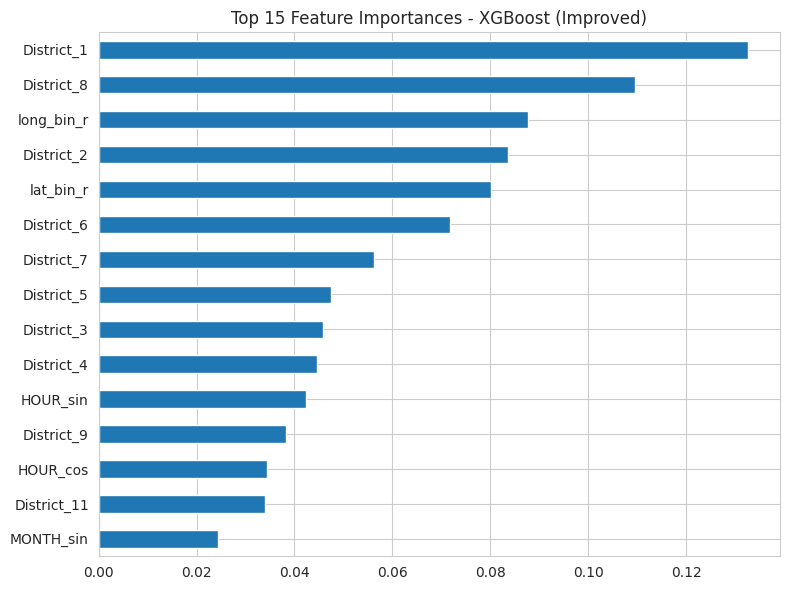

In [ ]:
from sklearn.model_selection import RandomizedSearchCV, KFold

# --- snap coordinates to the same ~500m grid used later in the notebook for hotspot evolution,
# instead of aggregating on raw (near-unique) floating point Lat/Long ---
GRID_SIZE = 0.005
df['lat_bin_r'] = (df['Lat'] / GRID_SIZE).round().astype(int) * GRID_SIZE
df['long_bin_r'] = (df['Long'] / GRID_SIZE).round().astype(int) * GRID_SIZE

risk_agg2 = (
    df.groupby(['lat_bin_r', 'long_bin_r', 'District', 'MONTH', 'HOUR', 'DAY'])['total_weight']
    .sum()
    .reset_index(name='risk_score')
)
print("Aggregated rows (grid-binned):", risk_agg2.shape)

# cyclical encodings
risk_agg2['HOUR_sin'] = np.sin(2 * np.pi * risk_agg2['HOUR'] / 24)
risk_agg2['HOUR_cos'] = np.cos(2 * np.pi * risk_agg2['HOUR'] / 24)
risk_agg2['MONTH_sin'] = np.sin(2 * np.pi * risk_agg2['MONTH'] / 12)
risk_agg2['MONTH_cos'] = np.cos(2 * np.pi * risk_agg2['MONTH'] / 12)

# risk_score is a sum of many total_weight values -> right skewed; log1p stabilizes variance
print("Skew before log1p:", risk_agg2['risk_score'].skew())
risk_agg2['risk_score_log'] = np.log1p(risk_agg2['risk_score'])

feature_cols_reg = ['lat_bin_r', 'long_bin_r', 'District', 'DAY', 'HOUR_sin', 'HOUR_cos',
                     'MONTH_sin', 'MONTH_cos']
X_reg2 = pd.get_dummies(risk_agg2[feature_cols_reg], columns=['District'], drop_first=True)
y_reg2 = risk_agg2['risk_score_log']

X_train_r2, X_test_r2, y_train_r2, y_test_r2 = train_test_split(
    X_reg2, y_reg2, test_size=0.2, random_state=42
)
X_train_r2, X_val_r2, y_train_r2, y_val_r2 = train_test_split(
    X_train_r2, y_train_r2, test_size=0.15, random_state=42
)

param_dist_xgb = {
    'n_estimators': [400, 600, 800],
    'max_depth': [4, 6, 8, 10],
    'learning_rate': [0.01, 0.03, 0.05, 0.1],
    'subsample': [0.6, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'min_child_weight': [1, 3, 5],
    'reg_alpha': [0, 0.1, 0.5],
    'reg_lambda': [1, 1.5, 2],
}

base_xgb = XGBRegressor(random_state=42, tree_method='hist', n_jobs=-1)

random_search_xgb = RandomizedSearchCV(
    estimator=base_xgb,
    param_distributions=param_dist_xgb,
    n_iter=30,
    cv=KFold(n_splits=5, shuffle=True, random_state=42),
    scoring='neg_root_mean_squared_error',
    n_jobs=-1,
    random_state=42,
)
random_search_xgb.fit(X_train_r2, y_train_r2)

best_xgb = XGBRegressor(
    **random_search_xgb.best_params_,
    random_state=42,
    tree_method='hist',
    n_jobs=-1,
    early_stopping_rounds=30,
)
best_xgb.fit(X_train_r2, y_train_r2, eval_set=[(X_val_r2, y_val_r2)], verbose=False)

pred_log = best_xgb.predict(X_test_r2)
pred_orig = np.expm1(pred_log)
true_orig = np.expm1(y_test_r2)

rmse_log = mean_squared_error(y_test_r2, pred_log) ** 0.5
r2_log = r2_score(y_test_r2, pred_log)
rmse_orig = mean_squared_error(true_orig, pred_orig) ** 0.5
r2_orig = r2_score(true_orig, pred_orig)

print(f"Best Params: {random_search_xgb.best_params_}")
print(f"RMSE (log scale):      {rmse_log:.3f}")
print(f"R^2  (log scale):      {r2_log:.3f}")
print(f"RMSE (original scale): {rmse_orig:.3f}")
print(f"R^2  (original scale): {r2_orig:.3f}")

importances_xgb = pd.Series(best_xgb.feature_importances_, index=X_reg2.columns).sort_values(ascending=False)
plt.figure(figsize=(8, 6))
importances_xgb.head(15).plot(kind='barh')
plt.title('Top 15 Feature Importances - XGBoost (Improved)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


### Risk Heatmap

In [ ]:
from datetime import datetime


query_month = datetime.now().month
query_hour = datetime.now().hour

# Get unique spatial bins and add time components
grid_cells = risk_agg2[['lat_bin_r', 'long_bin_r', 'District', 'DAY']].drop_duplicates().reset_index(drop=True)
grid_cells['MONTH'] = query_month
grid_cells['HOUR'] = query_hour

# Add cyclical features for prediction
grid_cells['HOUR_sin'] = np.sin(2 * np.pi * grid_cells['HOUR'] / 24)
grid_cells['HOUR_cos'] = np.cos(2 * np.pi * grid_cells['HOUR'] / 24)
grid_cells['MONTH_sin'] = np.sin(2 * np.pi * grid_cells['MONTH'] / 12)
grid_cells['MONTH_cos'] = np.cos(2 * np.pi * grid_cells['MONTH'] / 12)

# One-hot encode 'District' column, matching the training data's columns
# The columns should be in the same order as X_reg2 used for training

# Reconstruct the feature columns list in the order used for training best_xgb
# From X_reg2 kernel state: lat_bin_r, long_bin_r, DAY, HOUR_sin, HOUR_cos, MONTH_sin, MONTH_cos, District_X

# Get the feature columns from the trained model's input for consistent order
model_feature_columns = best_xgb.feature_names_in_

# Prepare the data for prediction, ensuring columns match the training set
# Create a DataFrame with the features needed for prediction
prediction_features = grid_cells[['lat_bin_r', 'long_bin_r', 'DAY', 'HOUR_sin', 'HOUR_cos',
                                  'MONTH_sin', 'MONTH_cos']].copy()

# Handle one-hot encoding for 'District', making sure all possible district columns are present
# and in the correct order, filling missing ones with 0
encoded_districts = pd.get_dummies(grid_cells['District'], prefix='District', drop_first=True)

# Ensure all district columns from training set are present in prediction_features, fill with 0 if not
for col in [c for c in model_feature_columns if 'District_' in c]:
    if col not in encoded_districts.columns:
        prediction_features[col] = 0
    else:
        prediction_features[col] = encoded_districts[col]

# Drop the original 'District' column from prediction_features if it was not already dropped
if 'District' in prediction_features.columns:
    prediction_features = prediction_features.drop(columns=['District'])

# Reorder columns to match the model's expected input
prediction_input = prediction_features[model_feature_columns]

grid_cells['predicted_risk'] = best_xgb.predict(prediction_input)

grid_cells['predicted_risk_norm'] = (
    (grid_cells['predicted_risk'] - grid_cells['predicted_risk'].min())
    / (grid_cells['predicted_risk'].max() - grid_cells['predicted_risk'].min())
) * 100

grid_cells.sort_values('predicted_risk_norm', ascending=False).head(10)

,lat_bin_r,long_bin_r,District,DAY,MONTH,HOUR,HOUR_sin,HOUR_cos,MONTH_sin,MONTH_cos,predicted_risk,predicted_risk_norm
4442,42.355,-71.060,0,5,8,16,-0.866025,-0.5,-0.866025,-0.5,1.690745,100.000000
4441,42.355,-71.060,0,6,8,16,-0.866025,-0.5,-0.866025,-0.5,1.680664,99.154152
4440,42.355,-71.060,0,4,8,16,-0.866025,-0.5,-0.866025,-0.5,1.662233,97.607689
4436,42.355,-71.060,0,0,8,16,-0.866025,-0.5,-0.866025,-0.5,1.630541,94.948601
4437,42.355,-71.060,0,1,8,16,-0.866025,-0.5,-0.866025,-0.5,1.628988,94.818291
4438,42.355,-71.060,0,2,8,16,-0.866025,-0.5,-0.866025,-0.5,1.595224,91.985306
4439,42.355,-71.060,0,3,8,16,-0.866025,-0.5,-0.866025,-0.5,1.579292,90.648537
4159,42.350,-71.085,8,4,8,16,-0.866025,-0.5,-0.866025,-0.5,1.451062,79.889351
4161,42.350,-71.085,8,5,8,16,-0.866025,-0.5,-0.866025,-0.5,1.448966,79.713501
3419,42.335,-71.075,8,6,8,16,-0.866025,-0.5,-0.866025,-0.5,1.446362,79.495003


In [ ]:
center_lat = grid_cells['lat_bin_r'].mean()
center_long = grid_cells['long_bin_r'].mean()

risk_map = folium.Map(location=[center_lat, center_long], zoom_start=12, tiles='cartodbpositron')

heat_data = grid_cells[['lat_bin_r', 'long_bin_r', 'predicted_risk_norm']].values.tolist()
HeatMap(heat_data, radius=12, blur=18, max_zoom=13).add_to(risk_map)

risk_map

### Select Highest Priority

In [ ]:
police_stations = pd.DataFrame([
    {'station': 'Station A', 'lat': grid_cells['Lat'].quantile(0.25), 'long': grid_cells['Long'].quantile(0.25)},
    {'station': 'Station B', 'lat': grid_cells['Lat'].quantile(0.50), 'long': grid_cells['Long'].quantile(0.50)},
    {'station': 'Station C', 'lat': grid_cells['Lat'].quantile(0.75), 'long': grid_cells['Long'].quantile(0.75)},
])
police_stations

,station,lat,long
0,Station A,42.289416,-71.115549
1,Station B,42.320493,-71.081323
2,Station C,42.347534,-71.061532


In [ ]:
def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0  # km
    phi1, phi2 = radians(lat1), radians(lat2)
    dphi = radians(lat2 - lat1)
    dlambda = radians(lon2 - lon1)
    a = sin(dphi / 2) ** 2 + cos(phi1) * cos(phi2) * sin(dlambda / 2) ** 2
    return 2 * R * atan2(sqrt(a), sqrt(1 - a))

def nearest_station(lat, lon):
    dists = police_stations.apply(
        lambda r: haversine(lat, lon, r['lat'], r['long']), axis=1
    )
    idx = dists.idxmin()
    return police_stations.loc[idx, 'station'], dists.loc[idx]

grid_cells[['nearest_station', 'dist_to_station_km']] = grid_cells.apply(
    lambda r: pd.Series(nearest_station(r['Lat'], r['Long'])), axis=1
)

grid_cells['priority_score'] = grid_cells['predicted_risk_norm'] / (1 + grid_cells['dist_to_station_km'])

target = grid_cells.sort_values('priority_score', ascending=False).iloc[0]
start_station = police_stations[police_stations['station'] == target['nearest_station']].iloc[0]

print("Target (highest priority) cell:")
print(target[['Lat', 'Long', 'predicted_risk_norm', 'nearest_station', 'dist_to_station_km', 'priority_score']])
print()
print("Dispatching from:", start_station['station'], f"({start_station['lat']:.5f}, {start_station['long']:.5f})")

Target (highest priority) cell:
Lat                    42.348624
Long                  -71.082776
predicted_risk_norm        100.0
nearest_station        Station C
dist_to_station_km      1.750071
priority_score         36.362701
Name: 13882, dtype: object

Dispatching from: Station C (42.34753, -71.06153)


---
## 3. Micro-Hotspots Clustering (Unsupervised Learning)

**Idea:** This model works in an unsupervised way. Instead of relying on the pre-made police `DISTRICT` boundaries, the model takes only the crime locations (`Lat`, `Long`) and discovers the real crime hotspots on its own, drawing their boundaries directly from the data.

**Features:** `Lat` and `Long` only.

**Approach:**
1. Filter the data to one specific crime type (e.g. Larceny).
2. Apply **DBSCAN** (a density-based clustering algorithm) instead of K-Means, because:
   - It doesn't need the number of clusters specified in advance.
   - It produces irregular, natural-shaped hotspots (not forced circles like K-Means), which matches how real crime hotspots look on the ground.
   - It automatically separates "real hotspots" from scattered noise points that don't repeat enough to matter.
3. Compute each hotspot's center, radius, and crime count, then rank them from most to least dangerous.
4. Plot the hotspots on an interactive map (Folium), as a first step toward a Streamlit deployment.


In [ ]:
# Load a fresh copy of the data that still has OFFENSE_CODE_GROUP,
# since that column was dropped from the main df earlier for the supervised models
crime_type_df = pd.read_csv(
    'crime.csv',
    encoding="latin1",
    low_memory=False
)

# Same coordinate cleaning steps used in the main pipeline
crime_type_df['Lat'] = crime_type_df['Lat'].fillna(0)
crime_type_df['Long'] = crime_type_df['Long'].fillna(0)
crime_type_df = crime_type_df[(crime_type_df['Lat'] > 40) & (crime_type_df['Long'] < -70)]
crime_type_df = crime_type_df.dropna(subset=['OFFENSE_CODE_GROUP'])

print("Top 10 most frequent crime types:")
crime_type_df['OFFENSE_CODE_GROUP'].value_counts().head(10)


Top 10 most frequent crime types:


OFFENSE_CODE_GROUP
Motor Vehicle Accident Response    31811
Larceny                            25842
Medical Assistance                 23122
Investigate Person                 18422
Other                              17568
Simple Assault                     15331
Vandalism                          15267
Drug Violation                     15032
Verbal Disputes                    13326
Towed                              11091
Name: count, dtype: int64

### Choose the target crime type

Change `TARGET_CRIME` to any value from the list above to discover its micro-hotspots.

In [ ]:
TARGET_CRIME = 'Larceny'  # change this to any crime type from the list above

crime_subset = crime_type_df.loc[
    crime_type_df['OFFENSE_CODE_GROUP'] == TARGET_CRIME, ['Lat', 'Long']
].reset_index(drop=True)

print(f"Number of '{TARGET_CRIME}' reports: {len(crime_subset)}")
crime_subset.head()


Number of 'Larceny' reports: 25842


,Lat,Long
0,42.347972,-71.078496
1,42.325794,-71.085638
2,42.336112,-71.046654
3,42.361110,-71.067414
4,42.331920,-71.052108


### Choosing the best `eps` value (K-distance Graph)

DBSCAN needs two main parameters: `eps` (the max distance between two points for them to count
as neighbors) and `min_samples` (the minimum number of points needed to form a hotspot). We use a
K-distance graph to pick `eps` objectively instead of guessing: the point where the curve bends
sharply (the "elbow") is usually the best value.

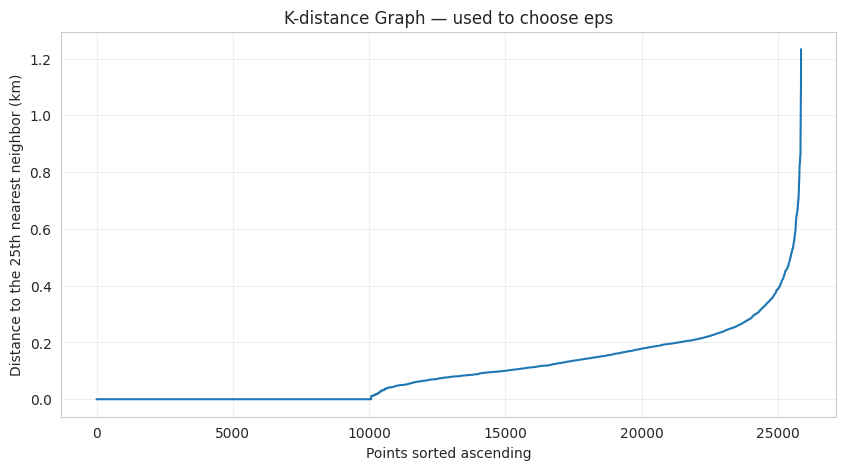

In [ ]:
from sklearn.neighbors import NearestNeighbors

MIN_SAMPLES = 25  # minimum number of reports required to count as a hotspot
# (raised from 15 -> 25: the raw coordinates contain a LOT of near-duplicate points,
# so a low min_samples let DBSCAN chain through the dense city core into one giant blob)

coords_rad = np.radians(crime_subset[['Lat', 'Long']].values)

neighbors = NearestNeighbors(n_neighbors=MIN_SAMPLES, metric='haversine')
neighbors_fit = neighbors.fit(coords_rad)
distances, _ = neighbors_fit.kneighbors(coords_rad)

# convert distances from radians to kilometers so the plot is readable
k_distances = np.sort(distances[:, -1]) * 6371.0

plt.figure(figsize=(10, 5))
plt.plot(k_distances)
plt.ylabel(f'Distance to the {MIN_SAMPLES}th nearest neighbor (km)')
plt.xlabel('Points sorted ascending')
plt.title('K-distance Graph — used to choose eps')
plt.grid(alpha=0.3)
plt.show()


### Applying DBSCAN

After picking an `eps` value from the elbow point in the graph above, we apply the model.

In [ ]:
from sklearn.cluster import DBSCAN

# NOTE: 0.2 km looked reasonable from the elbow graph, but the coordinates have heavy
# duplication (many reports geocoded to the same street corner), so at eps=0.2 DBSCAN chains
# through the dense city core and merges ~79% of all reports into a single 8km-radius cluster —
# defeating the whole point of finding *micro* hotspots. Lowering eps (together with the higher
# MIN_SAMPLES above) breaks that mega-cluster into much tighter, more meaningful hotspots.
EPS_KM = 0.08  # tightened from 0.2 -> 0.08 to stop the mega-cluster chaining issue
EPS_RAD = EPS_KM / 6371.0

dbscan = DBSCAN(eps=EPS_RAD, min_samples=MIN_SAMPLES, metric='haversine')
crime_subset['cluster'] = dbscan.fit_predict(coords_rad)

n_clusters = len(set(crime_subset['cluster'])) - (1 if -1 in crime_subset['cluster'].values else 0)
n_noise = int((crime_subset['cluster'] == -1).sum())

print(f"Number of hotspots discovered by the model: {n_clusters}")
print(f"Scattered reports (not part of any hotspot): {n_noise} out of {len(crime_subset)}")


Number of hotspots discovered by the model: 146
Scattered reports (not part of any hotspot): 11300 out of 25842


### Summarizing the hotspots: center, radius, and crime count for each one

In [ ]:
def haversine_km(lat1, lon1, lat2, lon2):
    R = 6371.0  # km
    phi1, phi2 = radians(lat1), radians(lat2)
    dphi = radians(lat2 - lat1)
    dlambda = radians(lon2 - lon1)
    a = sin(dphi / 2) ** 2 + cos(phi1) * cos(phi2) * sin(dlambda / 2) ** 2
    return 2 * R * atan2(sqrt(a), sqrt(1 - a))

hotspot_rows = []
for cluster_id, group in crime_subset[crime_subset['cluster'] != -1].groupby('cluster'):
    center_lat = group['Lat'].mean()
    center_long = group['Long'].mean()
    radius_km = group.apply(
        lambda r: haversine_km(center_lat, center_long, r['Lat'], r['Long']), axis=1
    ).max()
    hotspot_rows.append({
        'hotspot_id': int(cluster_id),
        'crime_count': len(group),
        'center_lat': center_lat,
        'center_long': center_long,
        'radius_km': radius_km,
    })

hotspots_df = (
    pd.DataFrame(hotspot_rows)
    .sort_values('crime_count', ascending=False)
    .reset_index(drop=True)
)
hotspots_df.insert(0, 'hotspot_name', ['Hotspot #' + str(i + 1) for i in hotspots_df.index])

hotspots_df


,hotspot_name,hotspot_id,crime_count,center_lat,center_long,radius_km
0,Hotspot #1,2,3041,42.355937,-71.059721,9.078497e-01
1,Hotspot #2,7,798,42.348624,-71.082776,2.465699e-12
2,Hotspot #3,0,547,42.347770,-71.078804,1.568260e-01
3,Hotspot #4,18,366,42.350959,-71.074128,1.167800e-12
4,Hotspot #5,11,316,42.334509,-71.075837,3.074082e-01
...,...,...,...,...,...,...
141,Hotspot #142,137,25,42.341378,-71.067680,8.624107e-02
142,Hotspot #143,144,25,42.346368,-71.075638,9.833821e-02
143,Hotspot #144,139,25,42.336512,-71.086018,8.897830e-02
144,Hotspot #145,136,24,42.346058,-71.080298,8.637605e-02


### Interactive map of the discovered crime hotspots

In [ ]:
center_lat_map = crime_subset['Lat'].mean()
center_long_map = crime_subset['Long'].mean()

hotspot_map = folium.Map(
    location=[center_lat_map, center_long_map], zoom_start=12, tiles='cartodbpositron'
)

# light heatmap background for all reports of the chosen crime type (including noise points)
HeatMap(
    crime_subset[['Lat', 'Long']].values.tolist(),
    radius=8, blur=12, min_opacity=0.15
).add_to(hotspot_map)

colors = ['red', 'darkred', 'orange', 'purple', 'darkblue',
          'green', 'darkgreen', 'cadetblue', 'black', 'pink']

for _, row in hotspots_df.iterrows():
    color = colors[int(row['hotspot_id']) % len(colors)]

    # the hotspot boundary drawn by the model itself
    folium.Circle(
        location=[row['center_lat'], row['center_long']],
        radius=max(row['radius_km'] * 1000, 60),  # meters
        color=color,
        weight=2,
        fill=True,
        fill_opacity=0.2,
        popup=folium.Popup(
            f"<b>{row['hotspot_name']}</b><br>"
            f"Crime type: {TARGET_CRIME}<br>"
            f"Report count: {row['crime_count']}<br>"
            f"Radius: {row['radius_km']:.2f} km",
            max_width=250,
        ),
    ).add_to(hotspot_map)

    folium.Marker(
        location=[row['center_lat'], row['center_long']],
        icon=folium.Icon(color=color, icon='exclamation-sign'),
        tooltip=f"{row['hotspot_name']} — {row['crime_count']} reports",
    ).add_to(hotspot_map)

hotspot_map


### Top hotspots by risk

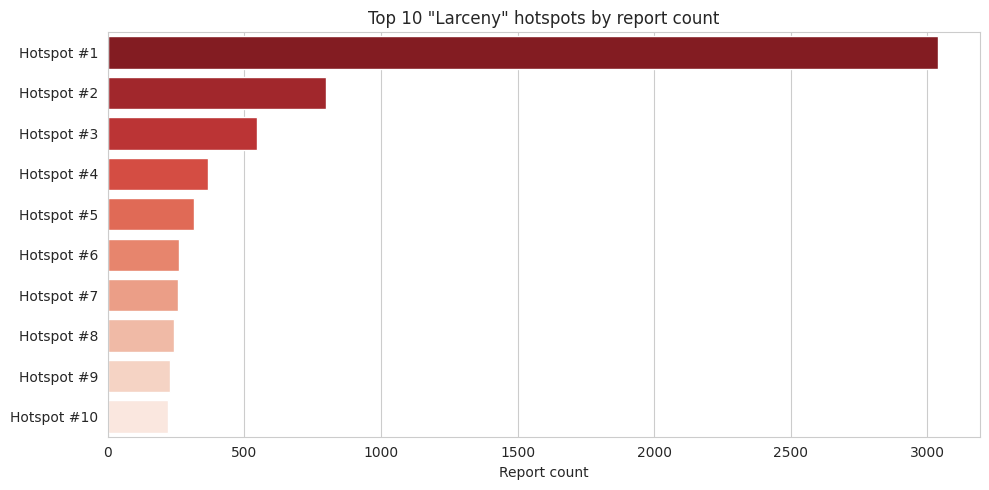

,hotspot_name,hotspot_id,crime_count,center_lat,center_long,radius_km
0,Hotspot #1,2,3041,42.355937,-71.059721,9.078497e-01
1,Hotspot #2,7,798,42.348624,-71.082776,2.465699e-12
2,Hotspot #3,0,547,42.347770,-71.078804,1.568260e-01
3,Hotspot #4,18,366,42.350959,-71.074128,1.167800e-12
4,Hotspot #5,11,316,42.334509,-71.075837,3.074082e-01
5,Hotspot #6,19,262,42.348406,-71.086883,2.335695e-12
6,Hotspot #7,30,258,42.329795,-71.083673,2.488426e-01
7,Hotspot #8,6,243,42.326966,-71.061986,0.000000e+00
8,Hotspot #9,25,229,42.375445,-71.039579,2.402532e-01
9,Hotspot #10,47,222,42.349274,-71.080345,1.209813e-01


In [ ]:
top_n = min(10, len(hotspots_df))
top_hotspots = hotspots_df.head(top_n)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=top_hotspots,
    x='crime_count', y='hotspot_name',
    hue='hotspot_name', palette='Reds_r', legend=False,
)
plt.title(f'Top {top_n} "{TARGET_CRIME}" hotspots by report count')
plt.xlabel('Report count')
plt.ylabel('')
plt.tight_layout()
plt.show()

top_hotspots


**Summary:** unlike the Random Forest and XGBoost models above, this model needs no labels and
doesn't rely on the pre-made `DISTRICT` split. It discovers micro-hotspots directly from where
crimes actually happened, giving finer geographic precision. It can be re-run for any other crime
type simply by changing `TARGET_CRIME`.

**Suggested next step:** turn this into a simple Streamlit app, with a dropdown to pick the crime
type and sliders for `eps` and `min_samples`, updating the map live — making it a ready-to-deploy
interactive tool.

---
## 4. Distance from Each Hotspot to the Nearest Real Police Station

The `Boston_Police_Stations__BPD_Only_.csv` file gives real station locations, but its `X`/`Y`
columns are in **Massachusetts State Plane (feet)**, not Lat/Long. We convert them to Lat/Long
first, then reuse the same haversine-distance idea already used earlier in this notebook to find,
for every hotspot, the nearest real station and how far it is.


In [ ]:
import pandas as pd
from pyproj import Transformer

stations_raw = pd.read_csv('Boston_Police_Stations_(BPD_Only).csv')

transformer = Transformer.from_crs('EPSG:2249', 'EPSG:4326', always_xy=True)

station_lon, station_lat = transformer.transform(stations_raw['X'].values, stations_raw['Y'].values)

real_police_stations = pd.DataFrame({
    'station': stations_raw['NAME'],
    'district': stations_raw['District'],
    'lat': station_lat,
    'long': station_lon
})

real_police_stations.head()

,station,district,lat,long
0,District E-18 Police Station,E18,42.256473,-71.124269
1,District E-5 Police Station,E5,42.286777,-71.148367
2,District A-7 Police Station,A7,42.381497,-71.028135
3,District A-1 Police Station,A1,42.361816,-71.060307
4,District D-14 Police Station,D14,42.349386,-71.150578


In [ ]:

stations_raw = pd.read_csv('Boston_Police_Stations_(BPD_Only).csv')

# EPSG:2249 = NAD83 / Massachusetts Mainland (US feet) -> EPSG:4326 = standard Lat/Long
transformer = Transformer.from_crs('EPSG:2249', 'EPSG:4326', always_xy=True)
station_lon, station_lat = transformer.transform(stations_raw['X'].values, stations_raw['Y'].values)

real_police_stations = pd.DataFrame({
    'station': stations_raw['NAME'],
    'district': stations_raw['District'],
    'lat': station_lat,
    'long': station_lon,
})

real_police_stations


,station,district,lat,long
0,District E-18 Police Station,E18,42.256473,-71.124269
1,District E-5 Police Station,E5,42.286777,-71.148367
2,District A-7 Police Station,A7,42.381497,-71.028135
3,District A-1 Police Station,A1,42.361816,-71.060307
4,District D-14 Police Station,D14,42.349386,-71.150578
5,District A-15 Police Station,A15,42.376458,-71.056047
6,District C-6 Police Station,C6,42.341155,-71.054936
7,District D-4 Police Station,D4,42.339431,-71.069239
8,Boston Police Headquarters,NaN,42.334184,-71.090747
9,District B-2 Police Station,B2,42.328377,-71.085684


### Nearest real station for each hotspot

In [ ]:
def nearest_real_station(lat, lon):
    dists = real_police_stations.apply(
        lambda r: haversine_km(lat, lon, r['lat'], r['long']), axis=1
    )
    idx = dists.idxmin()
    return real_police_stations.loc[idx, 'station'], dists.loc[idx]

hotspots_df[['nearest_station', 'dist_to_station_km']] = hotspots_df.apply(
    lambda r: pd.Series(nearest_real_station(r['center_lat'], r['center_long'])), axis=1
)

hotspots_df.sort_values('crime_count', ascending=False)


,hotspot_name,hotspot_id,crime_count,center_lat,center_long,radius_km,nearest_station,dist_to_station_km
0,Hotspot #1,2,3041,42.355937,-71.059721,9.078497e-01,District A-1 Police Station,0.655557
1,Hotspot #2,7,798,42.348624,-71.082776,2.465699e-12,District D-4 Police Station,1.510855
2,Hotspot #3,0,547,42.347770,-71.078804,1.568260e-01,District D-4 Police Station,1.215619
3,Hotspot #4,18,366,42.350959,-71.074128,1.167800e-12,District D-4 Police Station,1.343352
4,Hotspot #5,11,316,42.334509,-71.075837,3.074082e-01,District D-4 Police Station,0.770478
...,...,...,...,...,...,...,...,...
141,Hotspot #142,137,25,42.341378,-71.067680,8.624107e-02,District D-4 Police Station,0.251552
142,Hotspot #143,144,25,42.346368,-71.075638,9.833821e-02,District D-4 Police Station,0.933552
143,Hotspot #144,139,25,42.336512,-71.086018,8.897830e-02,Boston Police Headquarters,0.467006
144,Hotspot #145,136,24,42.346058,-71.080298,8.637605e-02,District D-4 Police Station,1.170064


**Reading this table:** each hotspot now shows the closest real BPD station and the distance to
it in km. A hotspot with a high `crime_count` **and** a large `dist_to_station_km` is a strong
candidate for extra patrol attention, since it's both busy and far from existing coverage.


---
### Bonus: replacing the placeholder stations in the "Select Highest Priority" section above

Earlier in this notebook (Section: *Select Highest Priority*), `police_stations` was built from
quantiles of the grid coordinates — just a placeholder. Now that we have real station locations,
we can redo that priority calculation using the real data instead.


In [ ]:
grid_cells[['nearest_station', 'dist_to_station_km']] = grid_cells.apply(
    lambda r: pd.Series(nearest_real_station(r['Lat'], r['Long'])), axis=1
)

grid_cells['priority_score'] = grid_cells['predicted_risk_norm'] / (1 + grid_cells['dist_to_station_km'])

target_real = grid_cells.sort_values('priority_score', ascending=False).iloc[0]

print("Target (highest priority) cell using REAL station data:")
print(target_real[['Lat', 'Long', 'predicted_risk_norm', 'nearest_station', 'dist_to_station_km', 'priority_score']])


Target (highest priority) cell using REAL station data:
Lat                                      42.361839
Long                                    -71.059765
predicted_risk_norm                      95.188316
nearest_station        District A-1 Police Station
dist_to_station_km                        0.044582
priority_score                           91.125711
Name: 16257, dtype: object


### Spatiotemporal Crime Hotspot Evolution

In [ ]:
# --- STEP 1: SPATIOTEMPORAL AGGREGATION & LAG FEATURES ---
# Define spatial grid (binning Lat/Long into spatial blocks) and time intervals
grid_size = 0.005  # ~500m x 500m grid cells
df['lat_bin'] = (df['Lat'] / grid_size).astype(int)
df['long_bin'] = (df['Long'] / grid_size).astype(int)

# Create a periodic time index (Year + Week of Year)
df['week_year'] = df['YEAR'].astype(str) + '_' + df['MONTH'].astype(str)

# Calculate aggregated weekly crime risk (sum of total_weight) per grid cell
grid_weekly = df.groupby(['lat_bin', 'long_bin', 'YEAR', 'MONTH'])['total_weight'].agg(
    historical_risk_sum='sum',
    crime_count='count'
).reset_index()

# Sort to prepare for shift/lag operations
grid_weekly = grid_weekly.sort_values(['lat_bin', 'long_bin', 'YEAR', 'MONTH'])

# Lag 1 Month/Period: Previous period's crime severity score in this cell
grid_weekly['prev_month_risk'] = grid_weekly.groupby(['lat_bin', 'long_bin'])['historical_risk_sum'].shift(1)

# Lag 2 Months: Trend detection
grid_weekly['prev_2month_risk'] = grid_weekly.groupby(['lat_bin', 'long_bin'])['historical_risk_sum'].shift(2)

# Hotspot Evolution Velocity: Rate of risk growth in the hotspot area
grid_weekly['hotspot_growth_rate'] = (
    (grid_weekly['prev_month_risk'] - grid_weekly['prev_2month_risk']) /
    (grid_weekly['prev_2month_risk'] + 1e-5)
)

# Rolling Spatial-Temporal Moving Average (3-period historical trend)
grid_weekly['hotspot_3m_avg_risk'] = grid_weekly.groupby(['lat_bin', 'long_bin'])['historical_risk_sum'].transform(
    lambda x: x.shift(1).rolling(window=3, min_periods=1).mean()
)

# --- STEP 2: MERGE BACK TO MAIN DATAFRAME ---
spatiotemporal_cols = ['lat_bin', 'long_bin', 'YEAR', 'MONTH']
df = df.merge(
    grid_weekly[spatiotemporal_cols + ['prev_month_risk', 'hotspot_growth_rate', 'hotspot_3m_avg_risk']],
    on=spatiotemporal_cols,
    how='left'
)

# Fill initial lag NaNs with zero (newly observed grid areas)
df[['prev_month_risk', 'hotspot_growth_rate', 'hotspot_3m_avg_risk']] = df[
    ['prev_month_risk', 'hotspot_growth_rate', 'hotspot_3m_avg_risk']
].fillna(0)

# Drop raw spatial bins if you don't want high-cardinality grid IDs
df_model = df.drop(columns=['lat_bin', 'long_bin'])

In [ ]:
# Display top 10 fastest-growing crime hotspots
print("--- Top 10 Emerging Hotspots (Highest Growth Rate) ---")
print(
    df[['Lat', 'Long', 'YEAR', 'MONTH', 'prev_month_risk', 'hotspot_growth_rate', 'hotspot_3m_avg_risk']]
    .sort_values(by='hotspot_growth_rate', ascending=False)
    .head(10)
)

print("\n--- Summary Statistics of Spatiotemporal Features ---")
print(df[['prev_month_risk', 'hotspot_growth_rate', 'hotspot_3m_avg_risk']].describe())

--- Top 10 Emerging Hotspots (Highest Growth Rate) ---
              Lat       Long  YEAR  MONTH  prev_month_risk  \
290837  42.291311 -71.168286  2015      8        12.594432   
287677  42.294728 -71.165124  2015      8        12.594432   
289234  42.294728 -71.165124  2015      8        12.594432   
287109  42.290309 -71.167915  2015      8        12.594432   
289360  42.294137 -71.165386  2015      8        12.594432   
264244  42.242600 -71.130350  2015     11        12.306750   
264953  42.244299 -71.133687  2015     11        12.306750   
265405  42.244230 -71.132519  2015     11        12.306750   
263912  42.243169 -71.134099  2015     11        12.306750   
263134  42.243169 -71.134099  2015     11        12.306750   

        hotspot_growth_rate  hotspot_3m_avg_risk  
290837            17.169677             6.643790  
287677            17.169677             6.643790  
289234            17.169677             6.643790  
287109            17.169677             6.643790  
289360 

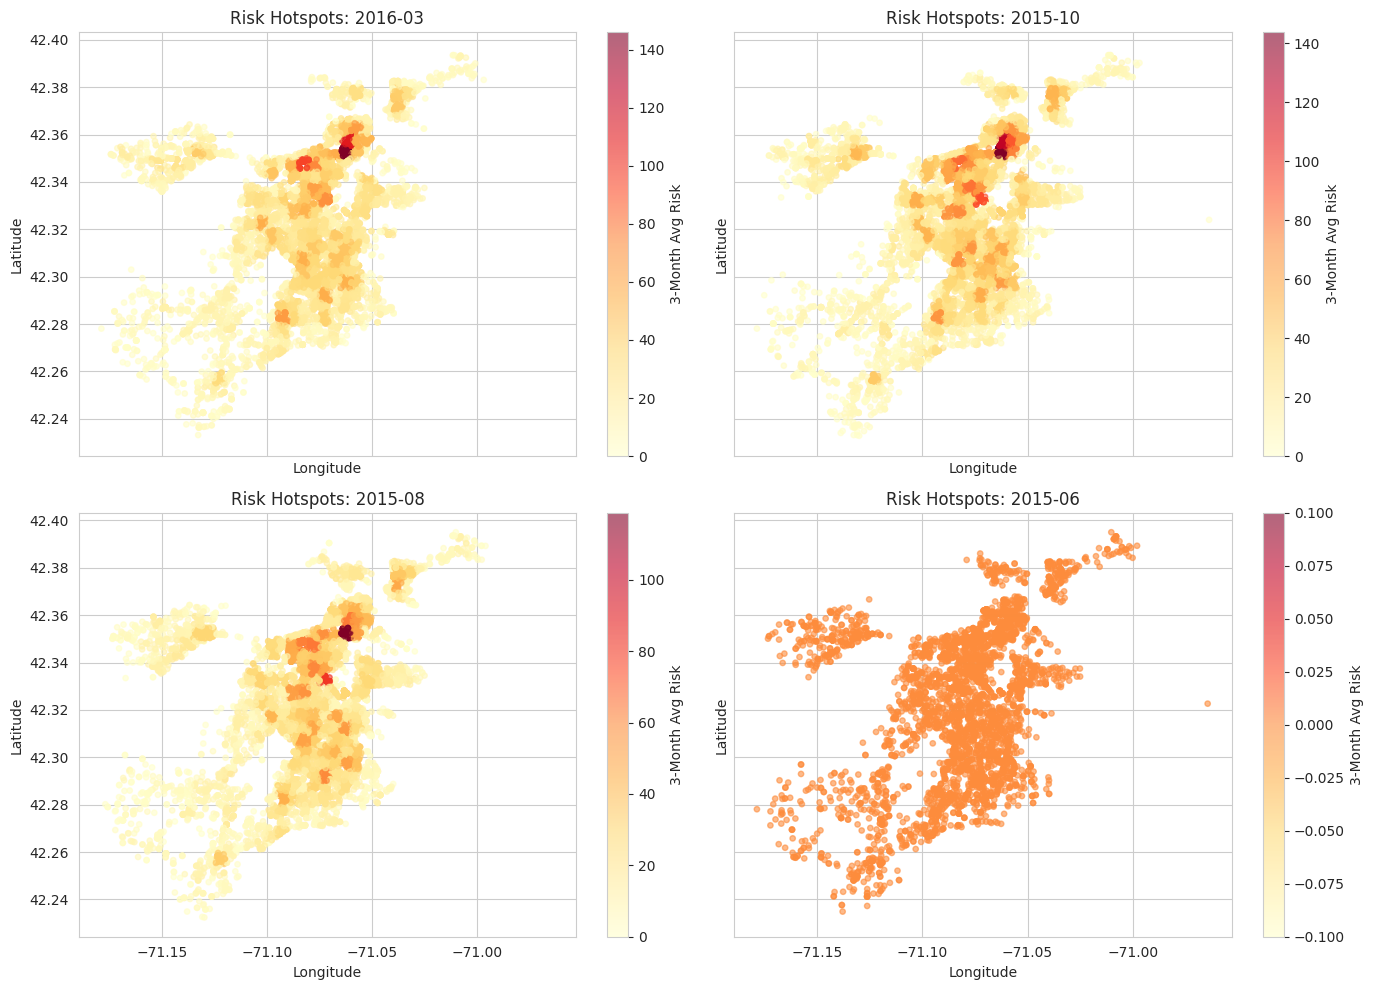

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot hotspot evolution across 4 recent periods
sample_months = df[['YEAR', 'MONTH']].drop_duplicates().tail(4).values

fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)
axes = axes.flatten()

for idx, (year, month) in enumerate(sample_months):
    subset = df[(df['YEAR'] == year) & (df['MONTH'] == month)]

    ax = axes[idx]
    scatter = ax.scatter(
        subset['Long'],
        subset['Lat'],
        c=subset['hotspot_3m_avg_risk'],
        cmap='YlOrRd',
        s=15,
        alpha=0.6
    )
    ax.set_title(f'Risk Hotspots: {year}-{month:02d}')
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')
    fig.colorbar(scatter, ax=ax, label='3-Month Avg Risk')

plt.tight_layout()
plt.show()

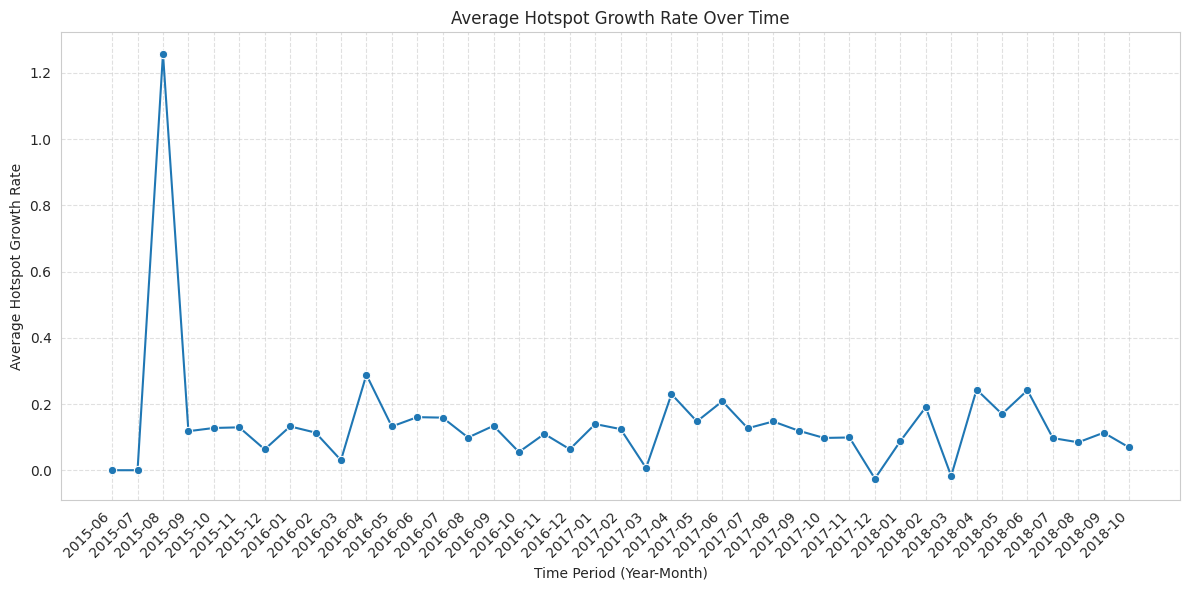

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Prepare data for time series plot of growth rate
growth_rate_ts = df.groupby(['YEAR', 'MONTH'])['hotspot_growth_rate'].mean().reset_index()

# Create a 'period' column for chronological sorting and plotting
growth_rate_ts['period'] = growth_rate_ts['YEAR'].astype(str) + '-' + growth_rate_ts['MONTH'].astype(str).str.zfill(2)
growth_rate_ts = growth_rate_ts.sort_values(by='period')

plt.figure(figsize=(12, 6))
sns.lineplot(x='period', y='hotspot_growth_rate', data=growth_rate_ts, marker='o')
plt.title('Average Hotspot Growth Rate Over Time')
plt.xlabel('Time Period (Year-Month)')
plt.ylabel('Average Hotspot Growth Rate')
plt.xticks(rotation=45, ha='right')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()
